# Projet 11 — Maintenance prédictive avec IoT et IA
## Notebook reproductible — AI4I / Random Forest
AI4I est synthétique. La cible décrit une panne courante, sans horizon de prédiction futur. Les mesures de vibration et de courant ne sont pas présentes. Source : [UCI, Matzka 2020](https://doi.org/10.24432/C5HS5C), CC BY 4.0.

In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
if root.name == 'notebooks': root = root.parent
os.chdir(root)
sys.path.insert(0, str(root))
import pandas as pd
from IPython.display import display, Image
from pdm.download import main as download
from pdm.train import main as train
download()
df = pd.read_csv('data/ai4i2020.csv')
display(df.head())

data\ai4i2020.csv dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## Exploration et déséquilibre
Vérifier les valeurs manquantes, la répartition des classes et les statistiques avant entraînement.

In [2]:
display(df.describe(include='all'))
display(df.isna().sum().to_frame('Valeurs manquantes'))
display(df['Machine failure'].value_counts().to_frame('Effectif'))

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
unique,NaN,10000,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,M24859,L,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,1,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,5000.50000,NaN,NaN,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,NaN,NaN,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,NaN,NaN,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,NaN,NaN,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,NaN,NaN,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,NaN,NaN,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000


,Valeurs manquantes
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


,Effectif
Machine failure,
0,9661
1,339


## Protocole expérimental
60 % entraînement, 20 % validation, 20 % test, stratifiés, graine 42. Le modèle utilise six variables disponibles en production, plus écart thermique et puissance. TWF/HDF/PWF/OSF/RNF, UDI et Product ID sont exclus. Aucun hyperparamètre n’est choisi sur le test. Le seuil 0,7 est imposé ; un autre seuil est exploré sur validation uniquement.

{
  "model_version": "rf-ai4i-dc6630cd9b",
  "sklearn_version": "1.6.1",
  "seed": 42,
  "dataset_rows": 10000,
  "failures": 339,
  "split_sizes": {
    "train": 6000,
    "validation": 2000,
    "test": 2000
  },
  "test_failure_count": 68,
  "average_precision": 0.8497367046228836,
  "roc_auc": 0.959562629399586,
  "brier_score": 0.011618027665680543,
  "baseline_all_healthy": {
    "threshold_strict_gt": 0.5,
    "precision": 0.0,
    "recall": 0.0,
    "f1": 0.0,
    "accuracy": 0.966,
    "confusion_matrix_tn_fp_fn_tp": [
      1932,
      0,
      68,
      0
    ]
  },
  "at_0_5": {
    "threshold_strict_gt": 0.5,
    "precision": 0.9038461538461539,
    "recall": 0.6911764705882353,
    "f1": 0.7833333333333333,
    "accuracy": 0.987,
    "confusion_matrix_tn_fp_fn_tp": [
      1927,
      5,
      21,
      47
    ]
  },
  "at_0_7": {
    "threshold_strict_gt": 0.7,
    "precision": 0.9714285714285714,
    "recall": 0.5,
    "f1": 0.6601941747572816,
    "accuracy": 0.9825,
 

,threshold_strict_gt,precision,recall,f1,accuracy,confusion_matrix_tn_fp_fn_tp
baseline_all_healthy,0.5,0.0,0.0,0.0,0.966,"[1932, 0, 68, 0]"
at_0_5,0.5,0.903846,0.691176,0.783333,0.987,"[1927, 5, 21, 47]"
at_0_7,0.7,0.971429,0.5,0.660194,0.9825,"[1931, 1, 34, 34]"
at_validation_threshold,0.39,0.854839,0.779412,0.815385,0.988,"[1923, 9, 15, 53]"


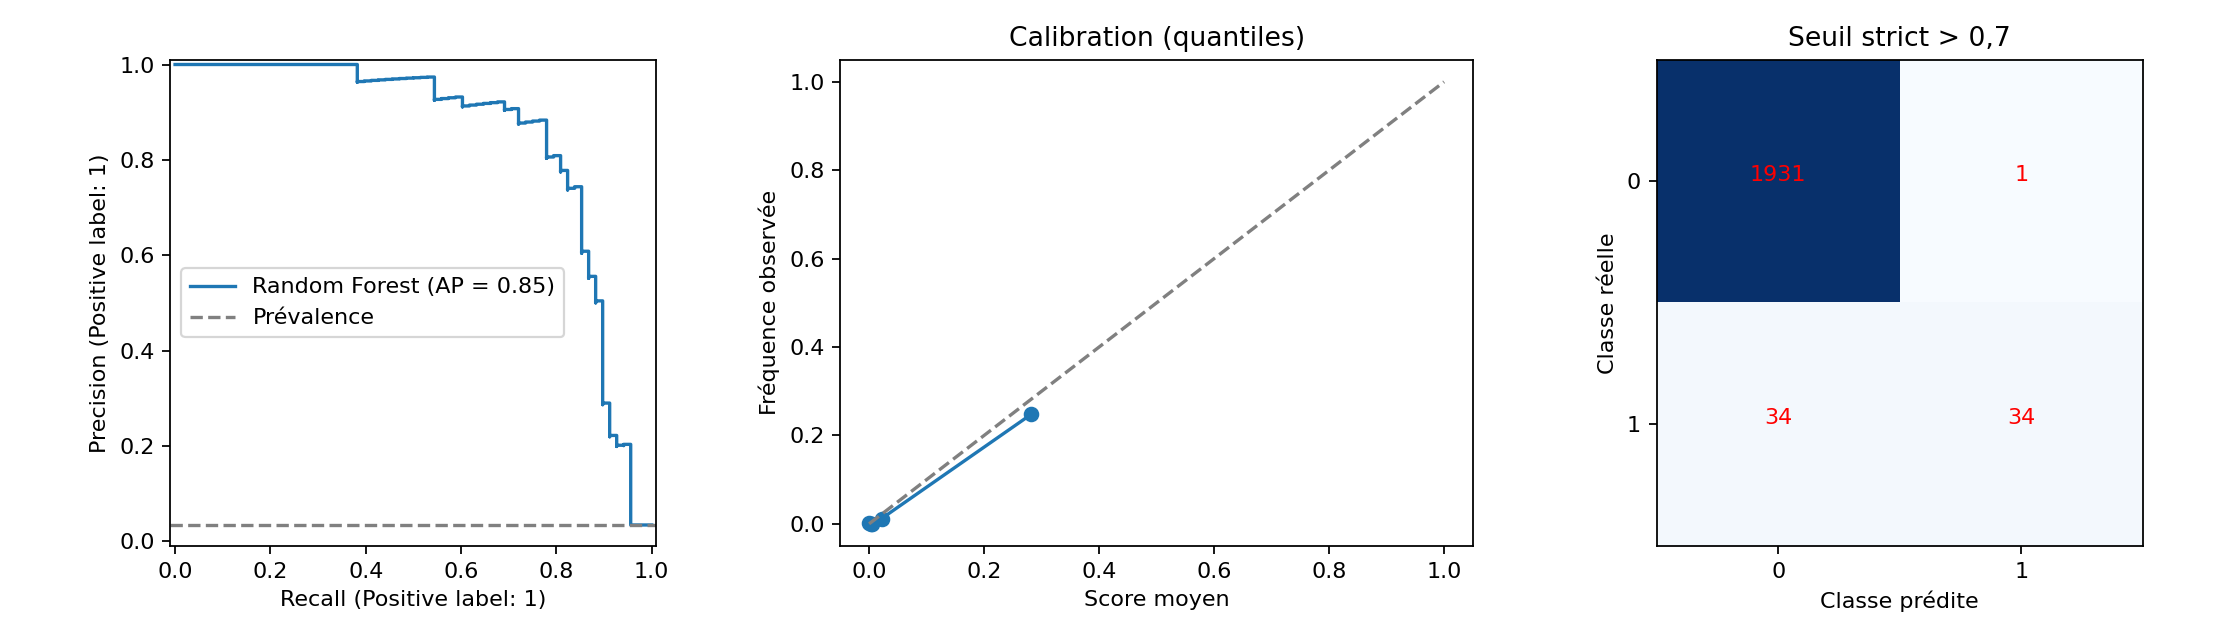

In [3]:
metrics = train()
display(pd.DataFrame({k:metrics[k] for k in ['baseline_all_healthy','at_0_5','at_0_7','at_validation_threshold']}).T)
display(Image(filename='reports/ml_evaluation.png'))

## Vérification des splits et de l’inférence
Le même pipeline de features est sérialisé et chargé par le service temps réel.

In [4]:
import joblib
from pdm.schema import FEATURES
splits = {name:pd.read_csv(f'data/{name}.csv') for name in ['train','validation','test']}
assert set(splits['train'].UDI).isdisjoint(splits['test'].UDI)
assert set(splits['validation'].UDI).isdisjoint(splits['test'].UDI)
artifact = joblib.load('models/random_forest.joblib')
print('Version :',artifact['version'])
print('Scores :',artifact['pipeline'].predict_proba(splits['test'][FEATURES].head())[:,1])

Version : rf-ai4i-dc6630cd9b


Scores : [0.22937979 0.         0.26671719 0.00635079 0.09503819]


## Conclusion et limites
Comparer précision, rappel, F1, Average Precision et Brier, plutôt que la seule accuracy. La calibration est diagnostiquée mais non corrigée. Un split aléatoire ne mesure pas la dérive temporelle. La maintenance prédictive à horizon défini demanderait des trajectoires comme NASA C-MAPSS, une cible RUL et un split par moteur. Les résultats du benchmark réseau figurent dans `reports/comparaison_protocoles.md`.